# Samuel — Classification Experimental Round 1

KASDAD TP2 · A06 KasdudLovers · Samuel

## tl;dr

**Structured + ordinary TF-IDF Logistic Regression (C2-B)** memimpin primary pada threshold 0,50: Macro F1 **0.8206**. Text-only memberi **0.8014**, dibanding **0.7145** untuk LR structured. Inner-selected threshold tidak otomatis meningkatkan hasil: hybrid primary menjadi **0.8188**.

Text sangat membantu saat stream tersedia, tetapi hybrid masih kalah dari structured-only pada stream kosong. H12 serta threshold stability tetap perlu diperhatikan. Ini kandidat sementara untuk review, **belum model final**.

## Context & Methods

Target resmi `artifact_signal`: 1 = indikasi artefak eksploit publik teramati; 0 = tidak teramati. Metric utama **Macro F1**, dua kelas selalu berurutan [0,1]. Target ini berbeda dari entry_friction TP1; cutoff dan recipe TP1 tidak disalin. Pertanyaan EDA formal Samuel tetap Regression.

### Key Assumptions

Cycle terurut mewakili disclosure yang makin baru; kalender absolut dan timing rinci fitur lain tetap provisional. Impact/EF resmi diizinkan pengguna. Semua evaluasi adalah development validation. H12 memakai ulang record primary dan bukan tambahan bukti independen. Leaderboard publik tidak dipakai memilih model/threshold.

Protokol dibekukan sebelum fit: 7 recipe × 8 window; enam outer histories berbeda, 42 outer fits +36 inner fits. W1/H12_E dan W4/H12_L memakai fit/threshold yang sama. Tidak ada official-test prediction atau all-Train final fit.

In [1]:
from pathlib import Path
import sys,json,io,contextlib
import pandas as pd
from IPython.display import display,Image

ROOT=Path.cwd().resolve()
while not (ROOT/'src/utils/paths.py').is_file() and ROOT!=ROOT.parent: ROOT=ROOT.parent
if not (ROOT/'src/utils/paths.py').is_file(): raise FileNotFoundError('Open inside the TP2 repository.')
sys.path.insert(0,str(ROOT))
from src.models.classification_evaluation import verify_freeze,load_protocol,run_classification
from src.models.classification_reporting import build_classification_report
from scripts.verify_classification_round1 import verify_results
freeze=verify_freeze(); protocol=load_protocol()
path=ROOT/'reports/classification_round1/results.json'
ready=False
if path.exists():
    old=json.loads(path.read_text(encoding='utf-8'))
    artifact=ROOT/'experiments/runs'/old['run_id']
    ready=old['status']=='CLASSIFICATION_ROUND1_COMPLETE_REVIEW_NO_FINAL_MODEL' and all(
        (artifact/f"fit{e}__{r['id']}.npz").is_file() and (artifact/f"fit{e}__{r['id']}.json").is_file()
        for e in old['unique_outer_histories'] for r in protocol['recipes'])
if not ready:
    print('Rebuilding missing frozen development cache; no search or Test prediction.')
    with contextlib.redirect_stdout(io.StringIO()): run_classification()
results=json.loads(path.read_text(encoding='utf-8'))
verification=verify_results()
paths=build_classification_report()
review=json.loads((ROOT/'reports/classification_round1/data_review.json').read_text(encoding='utf-8'))
P=results['aggregate']['primary']; H=results['aggregate']['secondary']
models=[r['id'] for r in protocol['recipes']]
FIG=ROOT/'reports/classification_round1/figures'
print(results['status'],results['total_evaluation_jobs'],'evaluation jobs')
print('Freeze:',freeze['signature'])
print('Independent sklearn reconciliation:',verification['status'])

CLASSIFICATION_ROUND1_COMPLETE_REVIEW_NO_FINAL_MODEL 56 evaluation jobs
Freeze: f30379ad9fd4e4679bf127d437a4b4c7e7979972fe9f6727f1e4477404094449
Independent sklearn reconciliation: PASS


## Data — classification support

Train 50.608 rows dengan 33.038 class 0 dan 17.570 class 1 (34,72%). Prevalence berubah non-monotonik antarperiode, sehingga cutoff yang cocok pada history sebelumnya belum tentu cocok pada cycle berikutnya. Ringkasan ini modeling support, bukan EDA formal baru; schema dan raw tetap memakai audit lama.

,cycles_inclusive,n,positive_rate
0,"[47, 57]",13546,0.306437
1,"[58, 68]",16736,0.410074
2,"[69, 79]",20326,0.322543


,entry_friction,n,positive_rate
0,0,34706,0.318706
1,1,15902,0.409320


,class,rows,missing_or_blank_rows,missing_or_blank_rate,present_rows
0,0,33038,2106,0.063745,30932
1,1,17570,1298,0.073876,16272


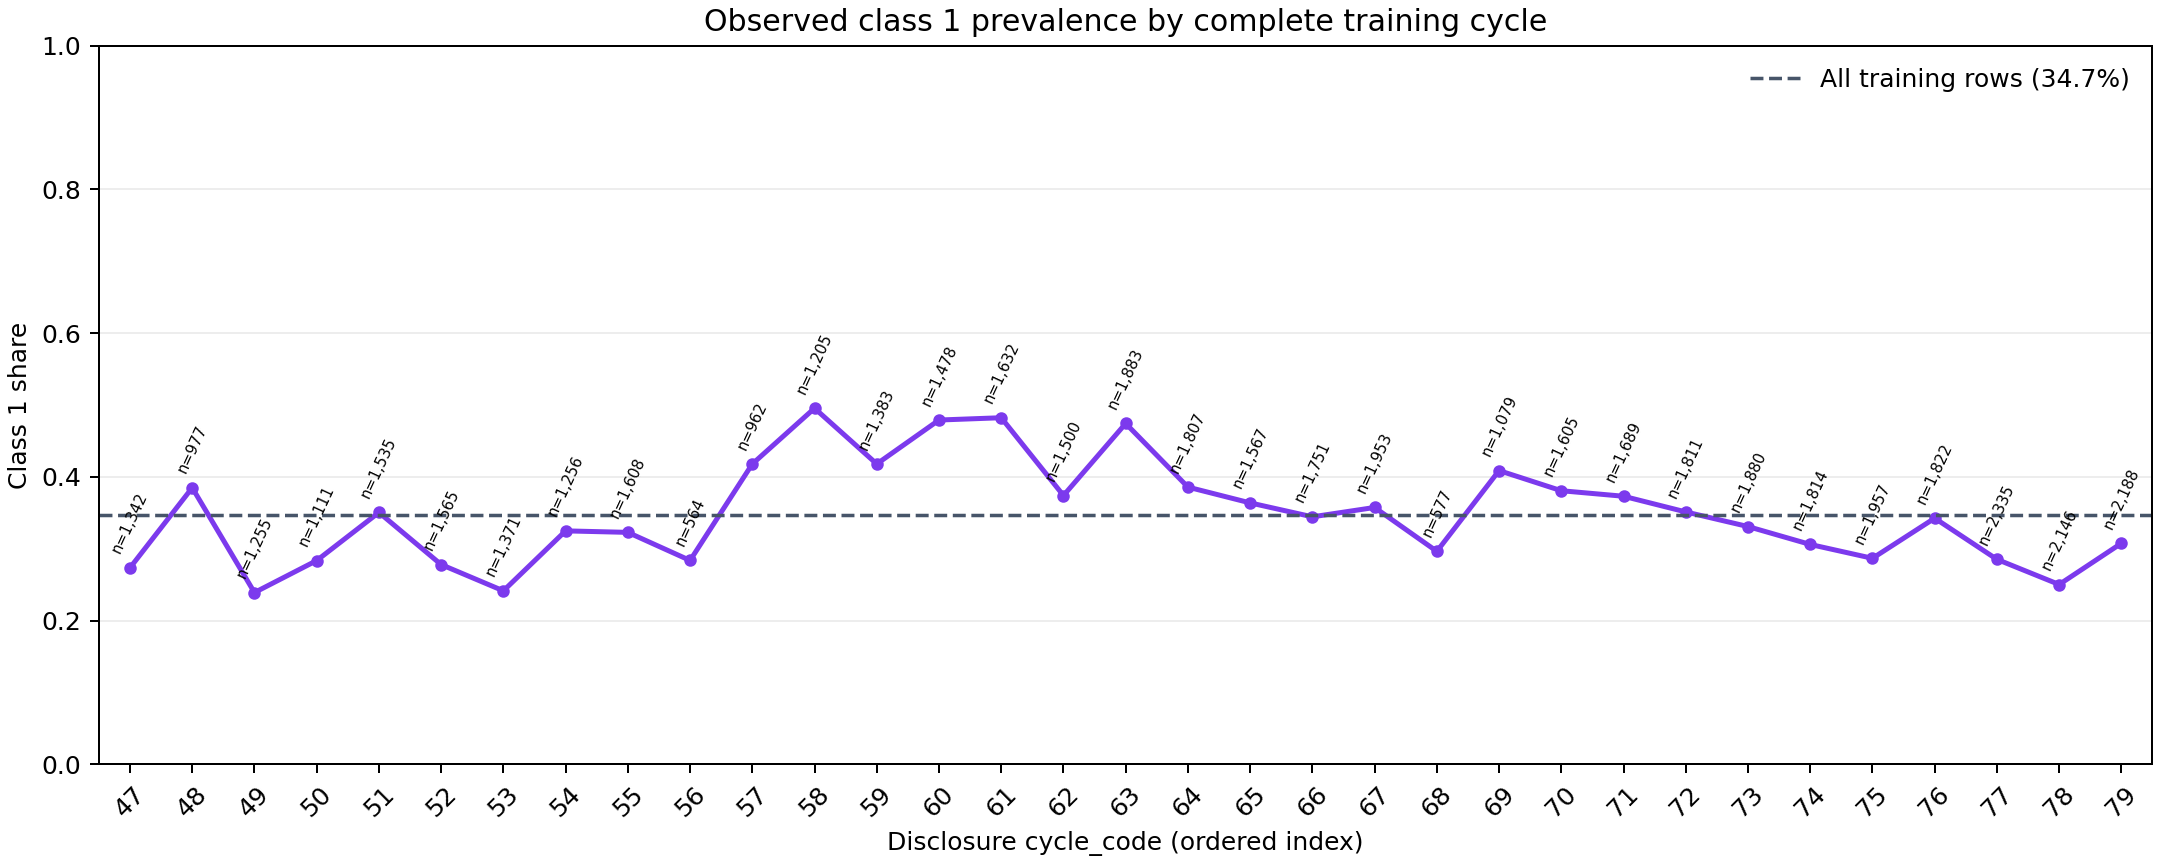

In [2]:
display(pd.DataFrame(review['by_cycle']['periods'])[['cycles_inclusive','n','positive_rate']])
display(pd.DataFrame(review['by_entry_friction']['overall'])[['entry_friction','n','positive_rate']])
display(pd.DataFrame([{'class':k,**v} for k,v in review['signal_stream']['train']['by_target_class'].items()])
        [['class','rows','missing_or_blank_rows','missing_or_blank_rate','present_rows']])
display(Image(filename=str(FIG/'classification_target_prevalence_by_cycle.png')))

## Results — fixed versus inner-selected

LR memakai C=1, liblinear, class_weight=None; HGB 200 iterations/15 leaves/learning rate 0,05, tanpa early stopping. TF-IDF word unigram+bigram dibatasi 20.000 fitur, min_df=3, max_df=0,995, sublinear TF. Semua vocabularies, IDF, imputer, scaler dan category mapping fit-only. Text kosong menjadi zero vector plus indicator.

Pooled F1 dihitung dari gabungan prediksi, sedangkan equal-cycle adalah rata-rata F1 setiap cycle. Jangan menyamakan kedua estimand ini.

In [3]:
rows=[]
for m in models:
    a=P['fixed_0.5'][m]; b=P['inner_selected'][m]
    rows.append({'model':m,'fixed F1':a['metrics']['macro_f1'],'selected F1':b['metrics']['macro_f1'],
      'fixed equal-cycle':a['equal_cycle_macro_f1'],'selected equal-cycle':b['equal_cycle_macro_f1'],
      'AP':a['metrics']['average_precision'],'fixed positive rate':a['metrics']['positive_prediction_rate'],
      'selected positive rate':b['metrics']['positive_prediction_rate']})
display(pd.DataFrame(rows).round(4))

,model,fixed F1,selected F1,fixed equal-cycle,selected equal-cycle,AP,fixed positive rate,selected positive rate
0,C0_A,0.3894,0.3894,0.3868,0.3868,0.3420,0.0000,0.0000
1,C0_B,0.3894,0.5469,0.3868,0.4533,0.3800,0.0000,0.3577
2,C0_C,0.3894,0.5549,0.3868,0.5393,0.4107,0.0000,0.4170
3,C1_A,0.7145,0.7112,0.7121,0.7101,0.6734,0.4169,0.4929
4,C1_B,0.7310,0.7333,0.7262,0.7295,0.7086,0.3264,0.4551
5,C2_A,0.8014,0.8057,0.7916,0.7956,0.8181,0.2969,0.3338
6,C2_B,0.8206,0.8188,0.8124,0.8110,0.8276,0.3509,0.3752


**Interpretasi:** dua fitur impact/EF mempunyai ranking signal terbatas dan pada threshold 0,50 seluruh prediksi menjadi class 0. Expanded structured features memperbaiki hasil besar; text-only kemudian mengungguli structured-only, dan hybrid menambah manfaat. C0-B merupakan peringatan: pooled score dapat terlihat lebih baik meskipun beberapa window memprediksi seluruh rows ke satu kelas. Periksa equal-cycle serta prediction rate, bukan satu aggregate saja.

### Semua window dan horizon panjang

W1–W6 memvalidasi cycle 56–59, 60–63, 64–67, 68–71, 72–75, 76–79. Fit mulai 47 dan berakhir tepat sebelum blok validation. H12_E memvalidasi 56–67 dari fit sampai 55; H12_L memvalidasi 68–79 dari fit sampai 67.

fixed_0.5


window,W1,W2,W3,W4,W5,W6,H12_E,H12_L
model,,,,,,,,
C0_A,0.3662,0.3531,0.3892,0.3849,0.4054,0.4137,0.3710,0.4041
C0_B,0.3662,0.3531,0.3892,0.3849,0.4054,0.4137,0.3710,0.4041
C0_C,0.3662,0.3531,0.3892,0.3849,0.4054,0.4137,0.3710,0.4041
C1_A,0.7200,0.7764,0.7285,0.7176,0.6605,0.6756,0.6973,0.6592
C1_B,0.7244,0.7662,0.7228,0.7241,0.7212,0.7037,0.6934,0.6849
C2_A,0.7493,0.8193,0.8037,0.8178,0.7937,0.7974,0.7669,0.7940
C2_B,0.7767,0.8471,0.8257,0.8409,0.8040,0.8056,0.7759,0.7994


inner_selected


window,W1,W2,W3,W4,W5,W6,H12_E,H12_L
model,,,,,,,,
C0_A,0.3662,0.3531,0.3892,0.3849,0.4054,0.4137,0.3710,0.4041
C0_B,0.3662,0.3123,0.5304,0.3849,0.5488,0.5732,0.3710,0.4041
C0_C,0.5454,0.5492,0.5032,0.5641,0.5433,0.5542,0.5390,0.5557
C1_A,0.7445,0.7452,0.7232,0.7153,0.6663,0.6733,0.7259,0.6583
C1_B,0.7451,0.7560,0.7210,0.7410,0.7053,0.7142,0.7252,0.6719
C2_A,0.7528,0.8253,0.8045,0.8202,0.7959,0.8046,0.7693,0.7933
C2_B,0.7857,0.8233,0.8250,0.8408,0.8029,0.8089,0.7827,0.8001


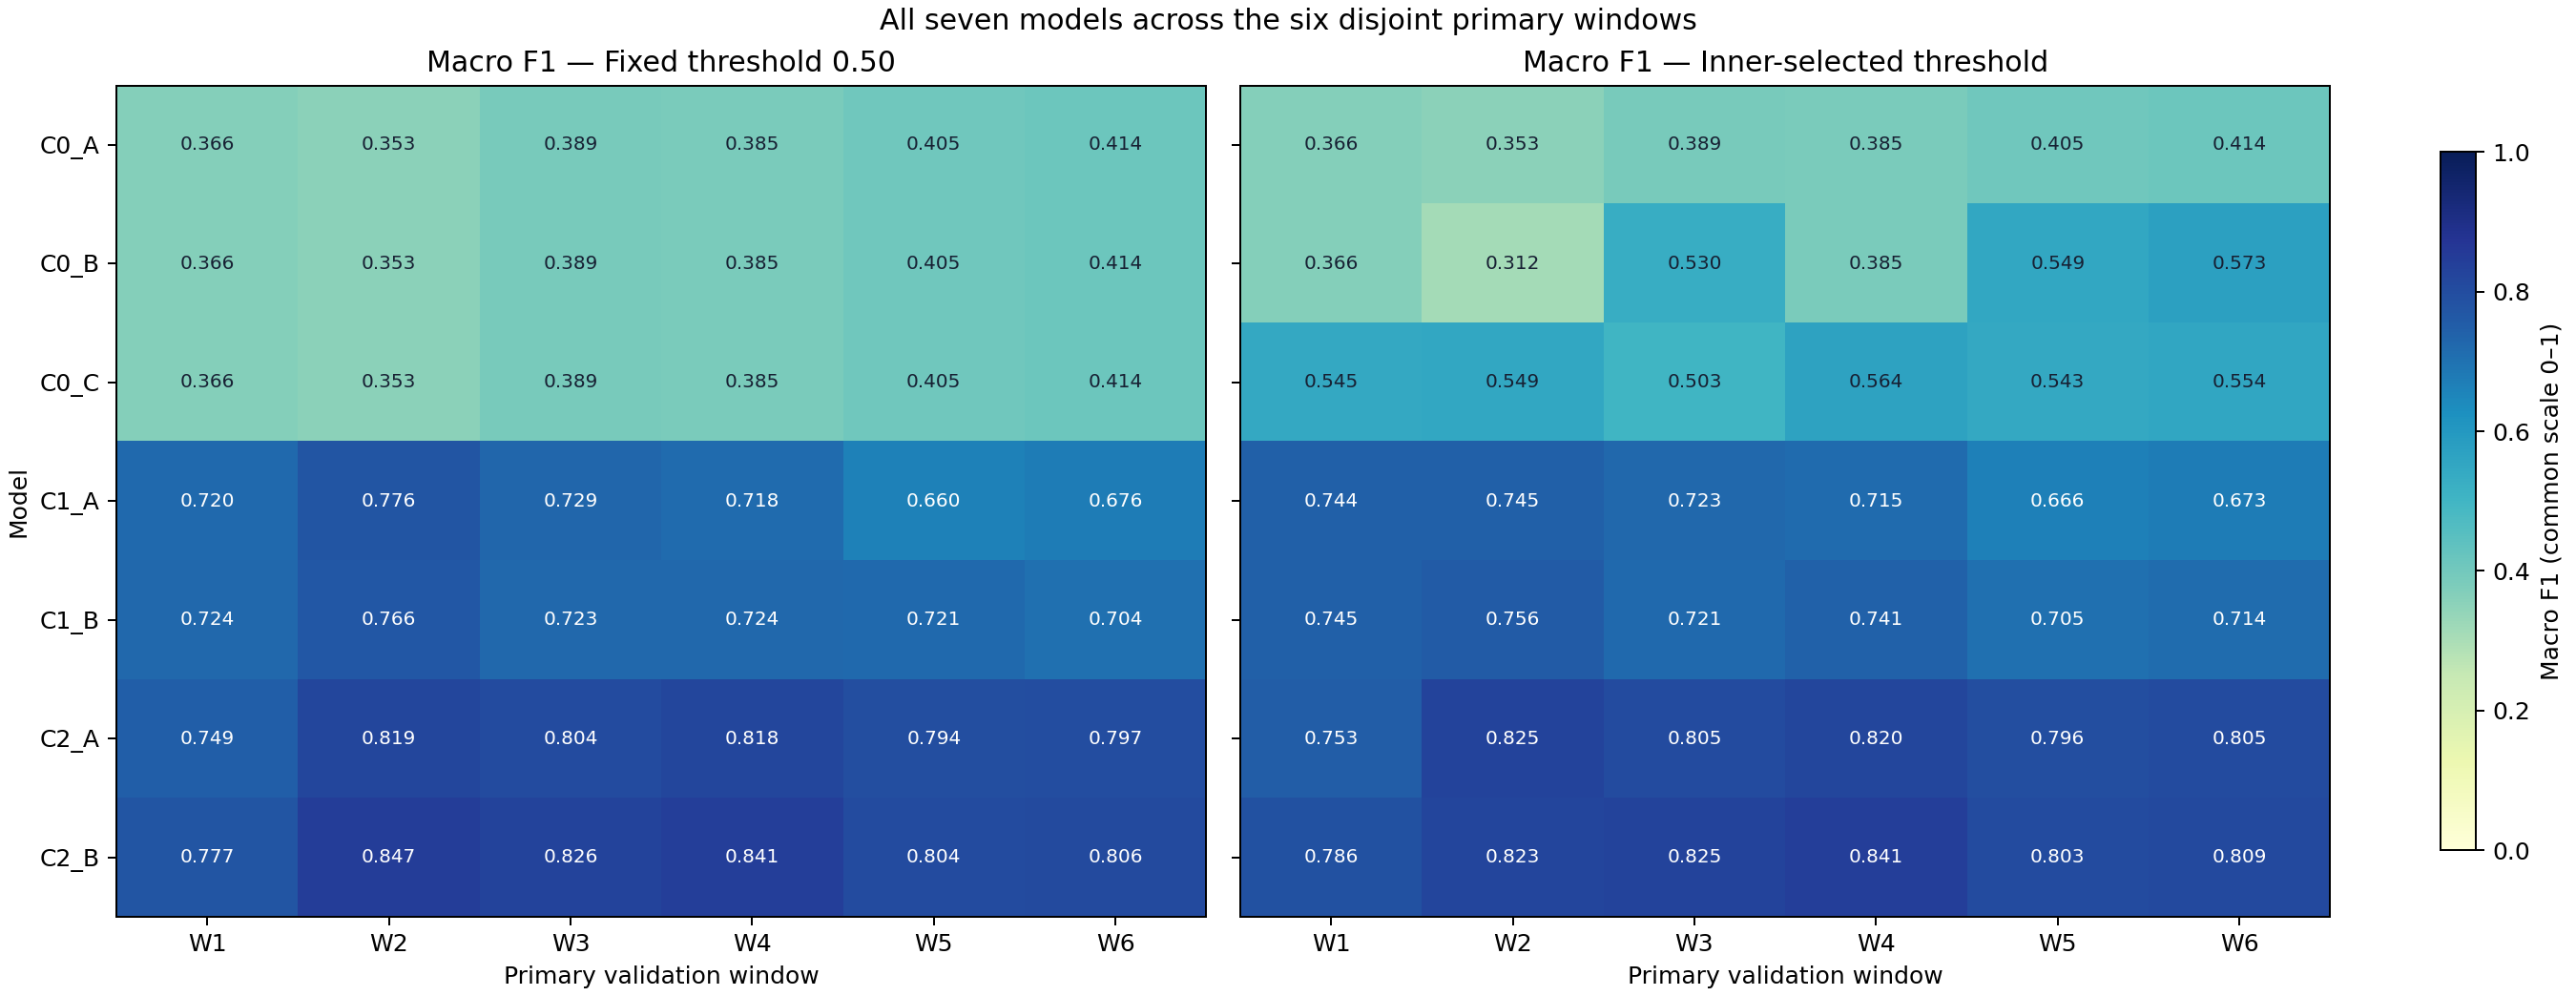

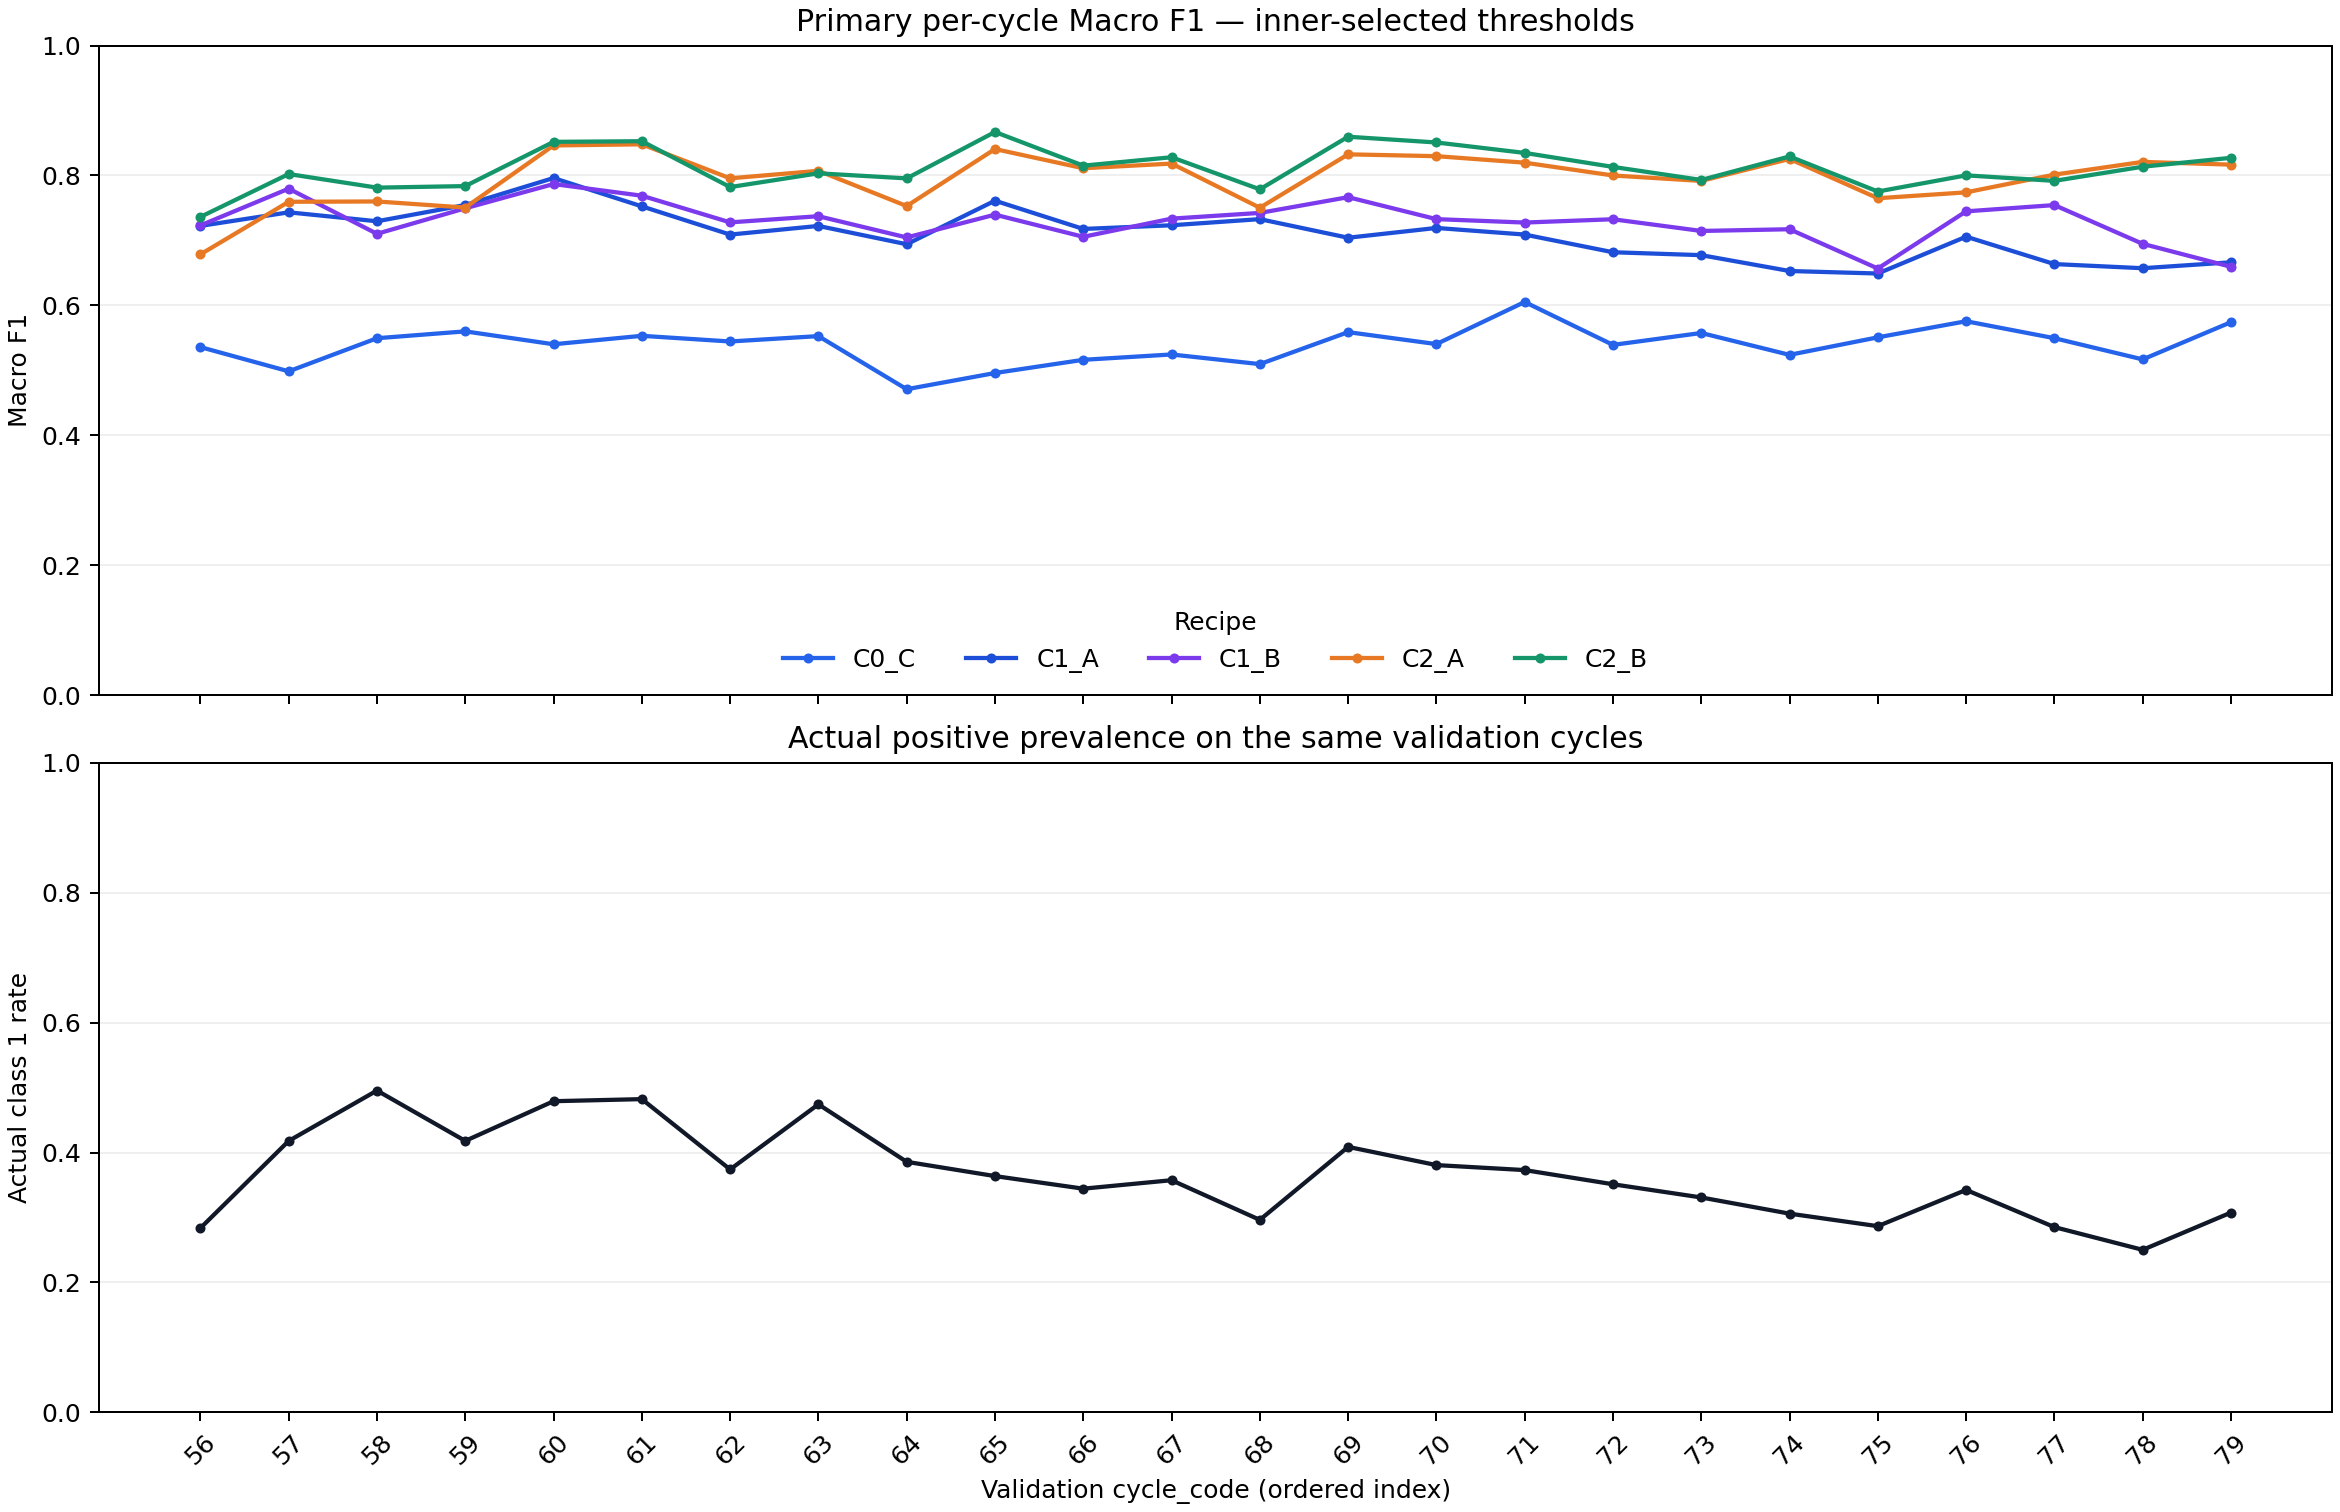

In [4]:
for policy in ['fixed_0.5','inner_selected']:
    print(policy)
    frame=pd.DataFrame([{'model':j['model'],'window':j['window'],'F1':j['policies'][policy]['metrics']['macro_f1']}
                       for j in results['jobs']])
    display(frame.pivot(index='model',columns='window',values='F1')[['W1','W2','W3','W4','W5','W6','H12_E','H12_L']].round(4))
display(Image(filename=str(FIG/'classification_primary_macro_f1_heatmaps.png')))
display(Image(filename=str(FIG/'classification_primary_per_cycle_f1.png')))

**Interpretasi:** text dan hybrid lebih kuat di cycle akhir daripada structured-only. Horizon 12 cycle menurunkan aggregate score dan memperkecil gain hybrid atas text-only. Pola ini tidak identik dengan Regression Round 1: regression expanded model terutama mempunyai counterexample pada H12 awal, sedangkan classification structured models mempunyai tantangan nyata pada periode akhir. Kedua task tetap menunjukkan perlunya horizon checks.

### Inner temporal threshold selection

Untuk fit berakhir E, inner fit = 47..E−4, inner validation = E−3..E. Threshold grid 0,10..0,90 step 0,01, tie terdekat 0,50 lalu lebih rendah; fallback 0,50 jika support/classes tidak cukup. Threshold dikunci, lalu model di-fit baru ke full outer history. Tidak ada outer label untuk selection/calibration.

In [5]:
cuts=[]
for end in results['unique_outer_histories']:
    audits=json.loads((ROOT/f'reports/classification_round1/fit_audits/fit{end}.json').read_text(encoding='utf-8'))
    for m,a in audits.items(): cuts.append({'model':m,'fit end':end,'threshold':a['selection']['threshold'],'fallback':a['selection']['fallback']})
display(pd.DataFrame(cuts).pivot(index='model',columns='fit end',values='threshold'))
display(pd.DataFrame([{'model':m,'H12 fixed F1':H['fixed_0.5'][m]['metrics']['macro_f1'],
                     'H12 selected F1':H['inner_selected'][m]['metrics']['macro_f1']} for m in models]).round(4))

fit end,55,59,63,67,71,75
model,,,,,,
C0_A,0.50,0.50,0.50,0.50,0.50,0.50
C0_B,0.31,0.30,0.36,0.42,0.41,0.41
C0_C,0.33,0.32,0.35,0.39,0.39,0.38
C1_A,0.45,0.32,0.46,0.51,0.42,0.45
C1_B,0.38,0.29,0.36,0.39,0.36,0.44
C2_A,0.48,0.40,0.39,0.42,0.47,0.43
C2_B,0.47,0.34,0.47,0.53,0.51,0.46


,model,H12 fixed F1,H12 selected F1
0,C0_A,0.3894,0.3894
1,C0_B,0.3894,0.3894
2,C0_C,0.3894,0.5511
3,C1_A,0.6768,0.6893
4,C1_B,0.6891,0.6963
5,C2_A,0.7819,0.7824
6,C2_B,0.7886,0.7924


**Interpretasi:** selected threshold memberi trade-off precision/recall dan tidak otomatis memperbaiki Macro F1. Pada hybrid primary, recall class 1 naik tetapi false positives bertambah lebih banyak; fixed 0,50 tetap kandidat pembanding penting. Threshold yang dipilih dari masa lalu bebas outer-label leakage, namun belum tentu stabil terhadap probability/prevalence shift.

## Error analysis — kelas, EF dan stream

Confusion rows=actual [0,1], columns=predicted [0,1]. AP adalah average precision; undefined class metrics diberi 0 dan single-class actual subsets ditandai pada JSON. AP/balanced accuracy null jika kedua kelas tidak ada.

,model,policy,precision1,recall1,F1 class0,F1 class1,FP,FN
0,C1_A,fixed_0.5,0.6088,0.7006,0.7775,0.6515,6293,4186
1,C1_A,inner_selected,0.5807,0.7900,0.7530,0.6694,7974,2936
2,C1_B,fixed_0.5,0.6829,0.6153,0.8147,0.6473,3995,5379
3,C1_B,inner_selected,0.6149,0.7723,0.7820,0.6847,6764,3183
4,C2_A,fixed_0.5,0.8145,0.6675,0.8691,0.7337,2125,4649
5,C2_A,inner_selected,0.7785,0.7173,0.8647,0.7466,2854,3953
6,C2_B,fixed_0.5,0.7817,0.7570,0.8721,0.7692,2955,3397
7,C2_B,inner_selected,0.7579,0.7849,0.8663,0.7712,3505,3007


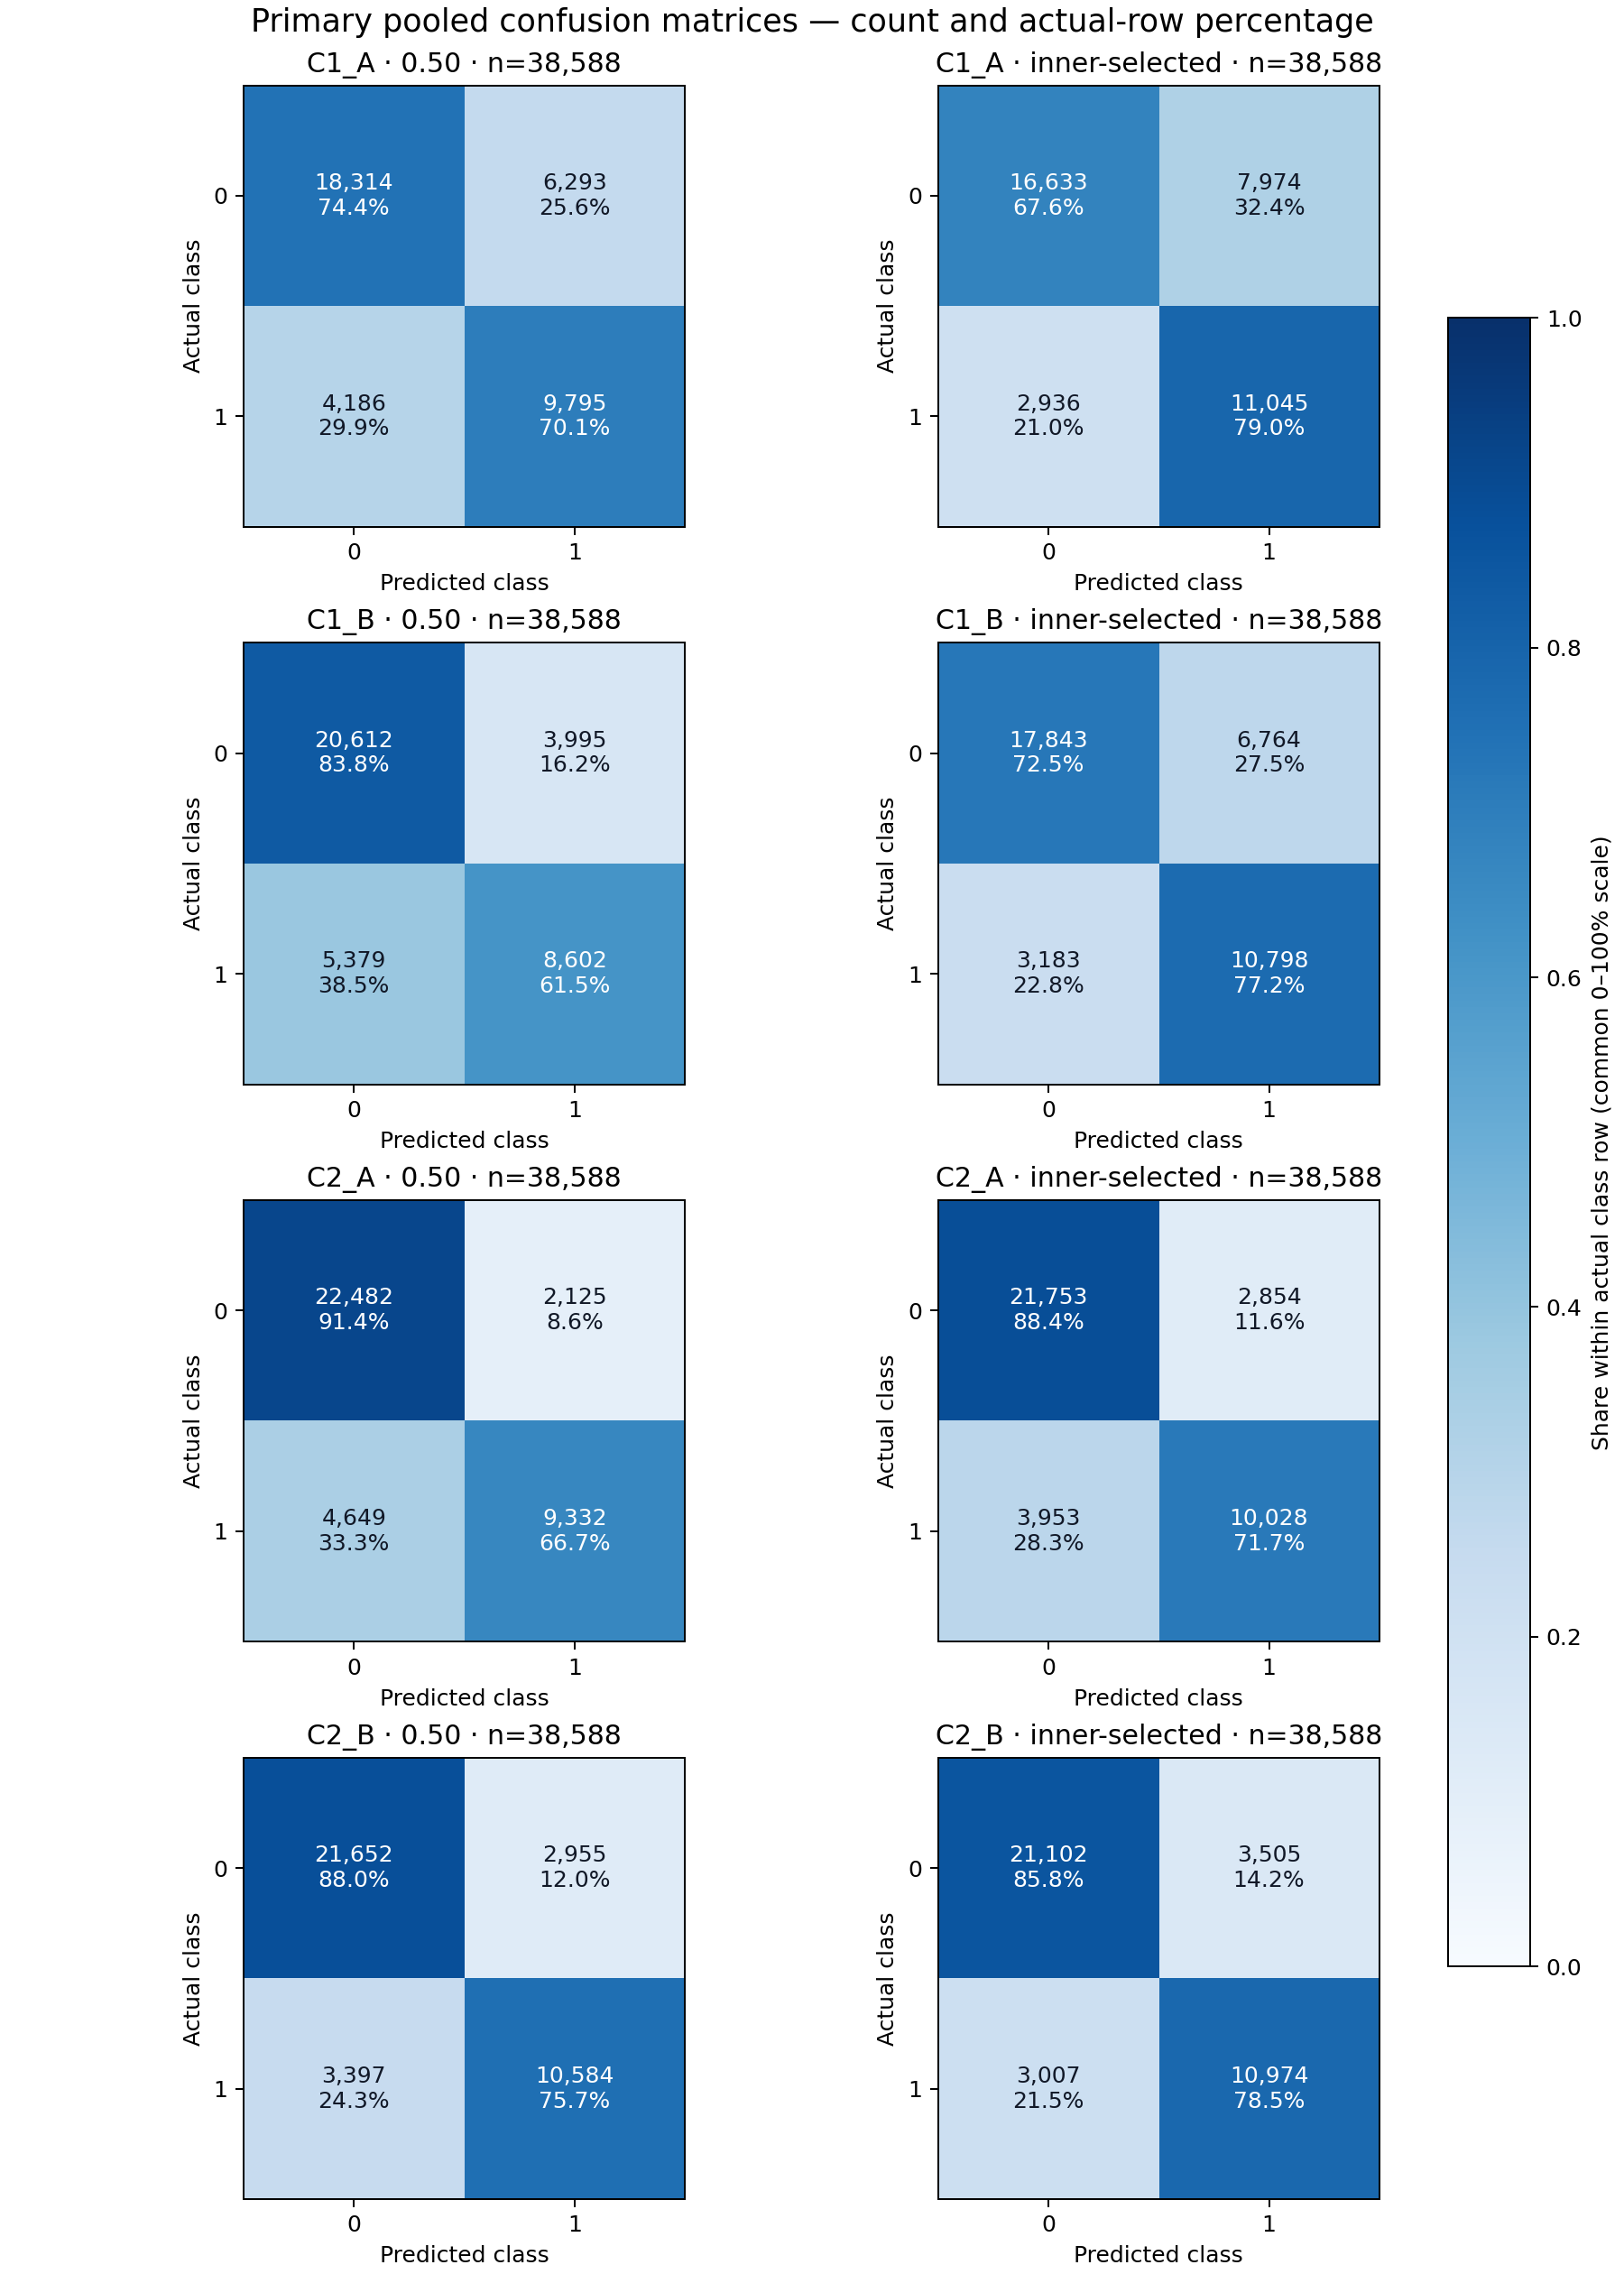

In [6]:
rows=[]
for m in ['C1_A','C1_B','C2_A','C2_B']:
    for policy in ['fixed_0.5','inner_selected']:
        a=P[policy][m]['metrics']
        rows.append({'model':m,'policy':policy,'precision1':a['per_class'][1]['precision'],
            'recall1':a['per_class'][1]['recall'],'F1 class0':a['per_class'][0]['f1'],
            'F1 class1':a['per_class'][1]['f1'],'FP':a['false_positive'],'FN':a['false_negative']})
display(pd.DataFrame(rows).round(4))
display(Image(filename=str(FIG/'classification_primary_confusion_matrices.png')))

### Missing stream adalah trade-off penting

Text-only memprediksi class 0 untuk seluruh stream kosong. Hybrid memperbaiki kasus itu dibanding text-only, tetapi masih kalah dari structured-only pada subset yang sama. Zero text vector tidak menjaga coefficients/intercept model gabungan tetap sama; missing indicator dan block scaling juga dapat berperan. Belum ada ablation untuk memisahkan penjelasan tersebut.

Perbandingan model di dalam subgroup memakai records yang sama. Perbandingan antar-subgroup memiliki prevalence berbeda dan tidak membuktikan penyebab kesulitan. Unknown dan missing code groups bisa overlap.

,model,group,n,positive prevalence,F1 fixed,recall1
0,C1_A,EF0,26048,0.3264,0.7116,0.6962
1,C1_A,EF1,12540,0.4368,0.7139,0.7074
2,C1_A,stream_missing,2578,0.4259,0.7596,0.8151
3,C1_A,stream_present,36010,0.3578,0.7106,0.6908
4,C1_B,EF0,26048,0.3264,0.7334,0.5968
5,C1_B,EF1,12540,0.4368,0.7177,0.6438
6,C1_B,stream_missing,2578,0.4259,0.7817,0.7468
7,C1_B,stream_present,36010,0.3578,0.7265,0.6041
8,C2_A,EF0,26048,0.3264,0.8079,0.6466
9,C2_A,EF1,12540,0.4368,0.7817,0.6999


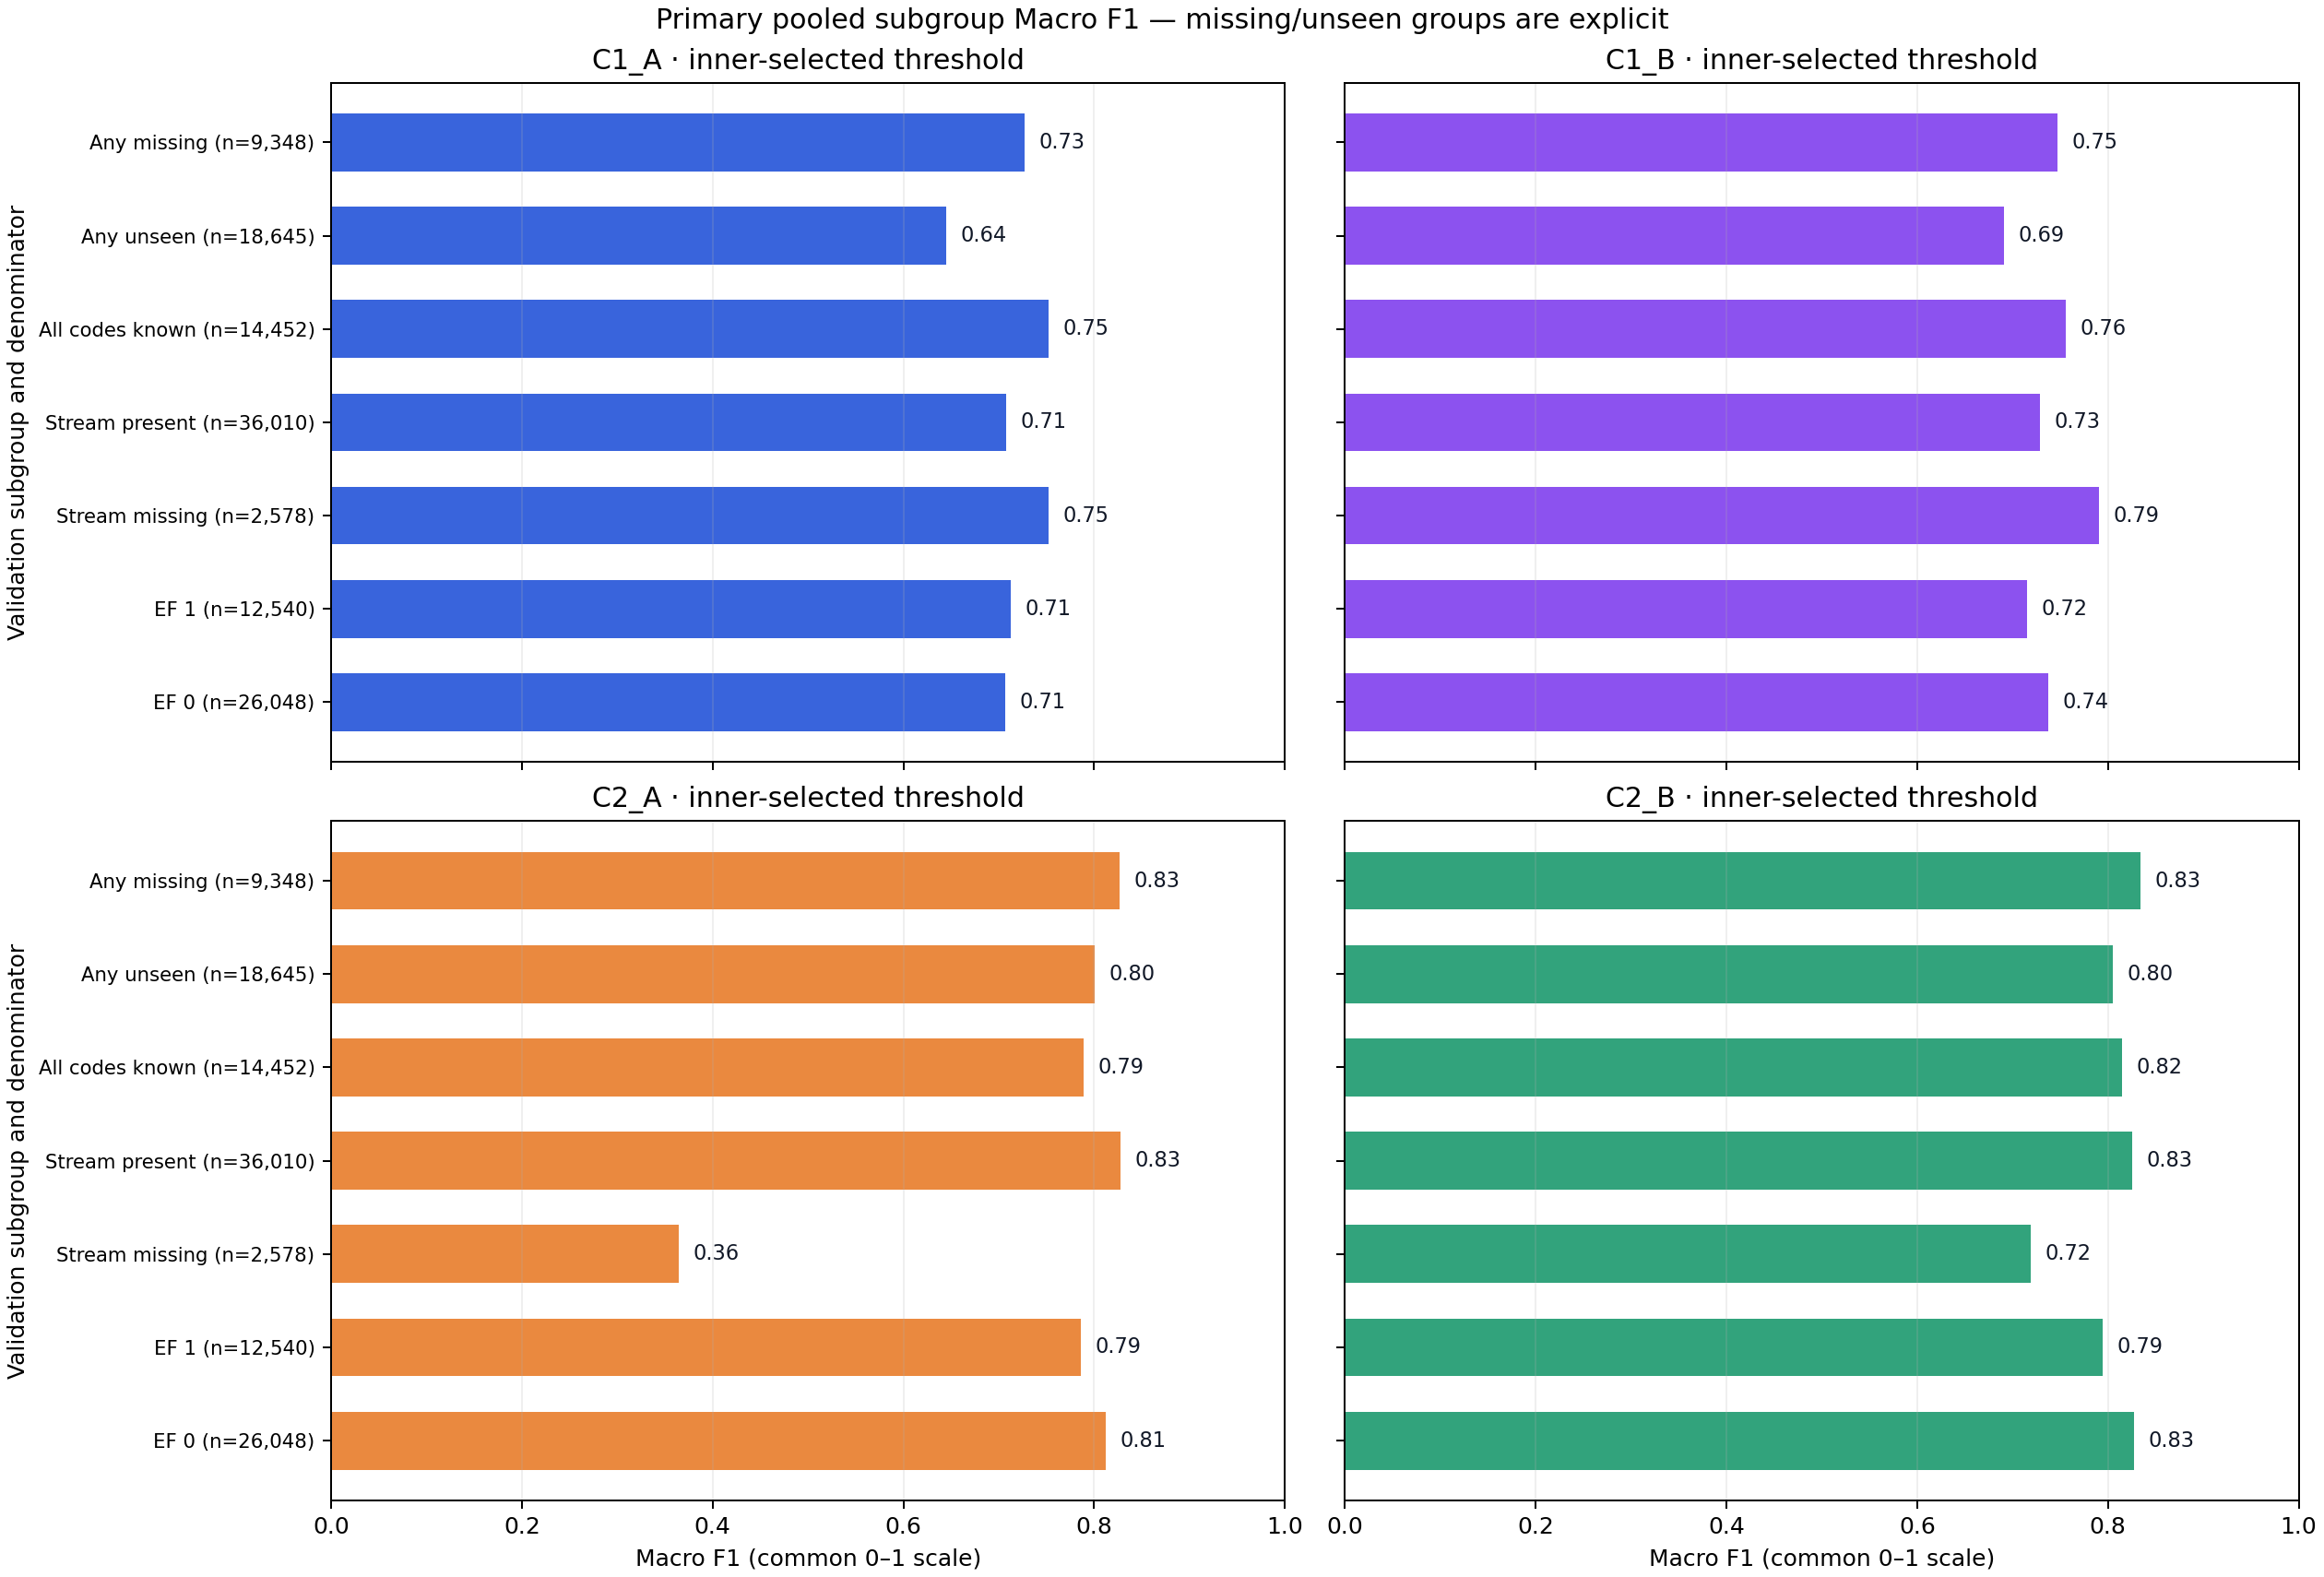

In [7]:
rows=[]
for m in ['C1_A','C1_B','C2_A','C2_B']:
    for name in ['EF0','EF1','stream_missing','stream_present']:
        a=P['fixed_0.5'][m]['subgroups'][name]
        rows.append({'model':m,'group':name,'n':a['n'],'positive prevalence':a['positive_rate'],
                     'F1 fixed':a['macro_f1'],'recall1':a['per_class'][1]['recall']})
display(pd.DataFrame(rows).round(4))
display(Image(filename=str(FIG/'classification_primary_subgroup_f1.png')))

## Probability behavior dan diagnostic history

Reliability memakai 10 bin tetap; tiap point melaporkan predicted probability dan observed positive rate. Ini diagnostic, tanpa calibration fitting. Prediksi H12 dan primary yang sudah tersedia juga dapat dibandingkan pada record sama; history era dan jumlah rows berubah bersamaan, sehingga belum merupakan atribusi kausal recency.

,model,Brier,mean probability,actual prevalence
0,C1_A,0.1690,0.4001,0.3623
1,C1_B,0.1593,0.3500,0.3623
2,C2_A,0.1259,0.3654,0.3623
3,C2_B,0.1187,0.3707,0.3623


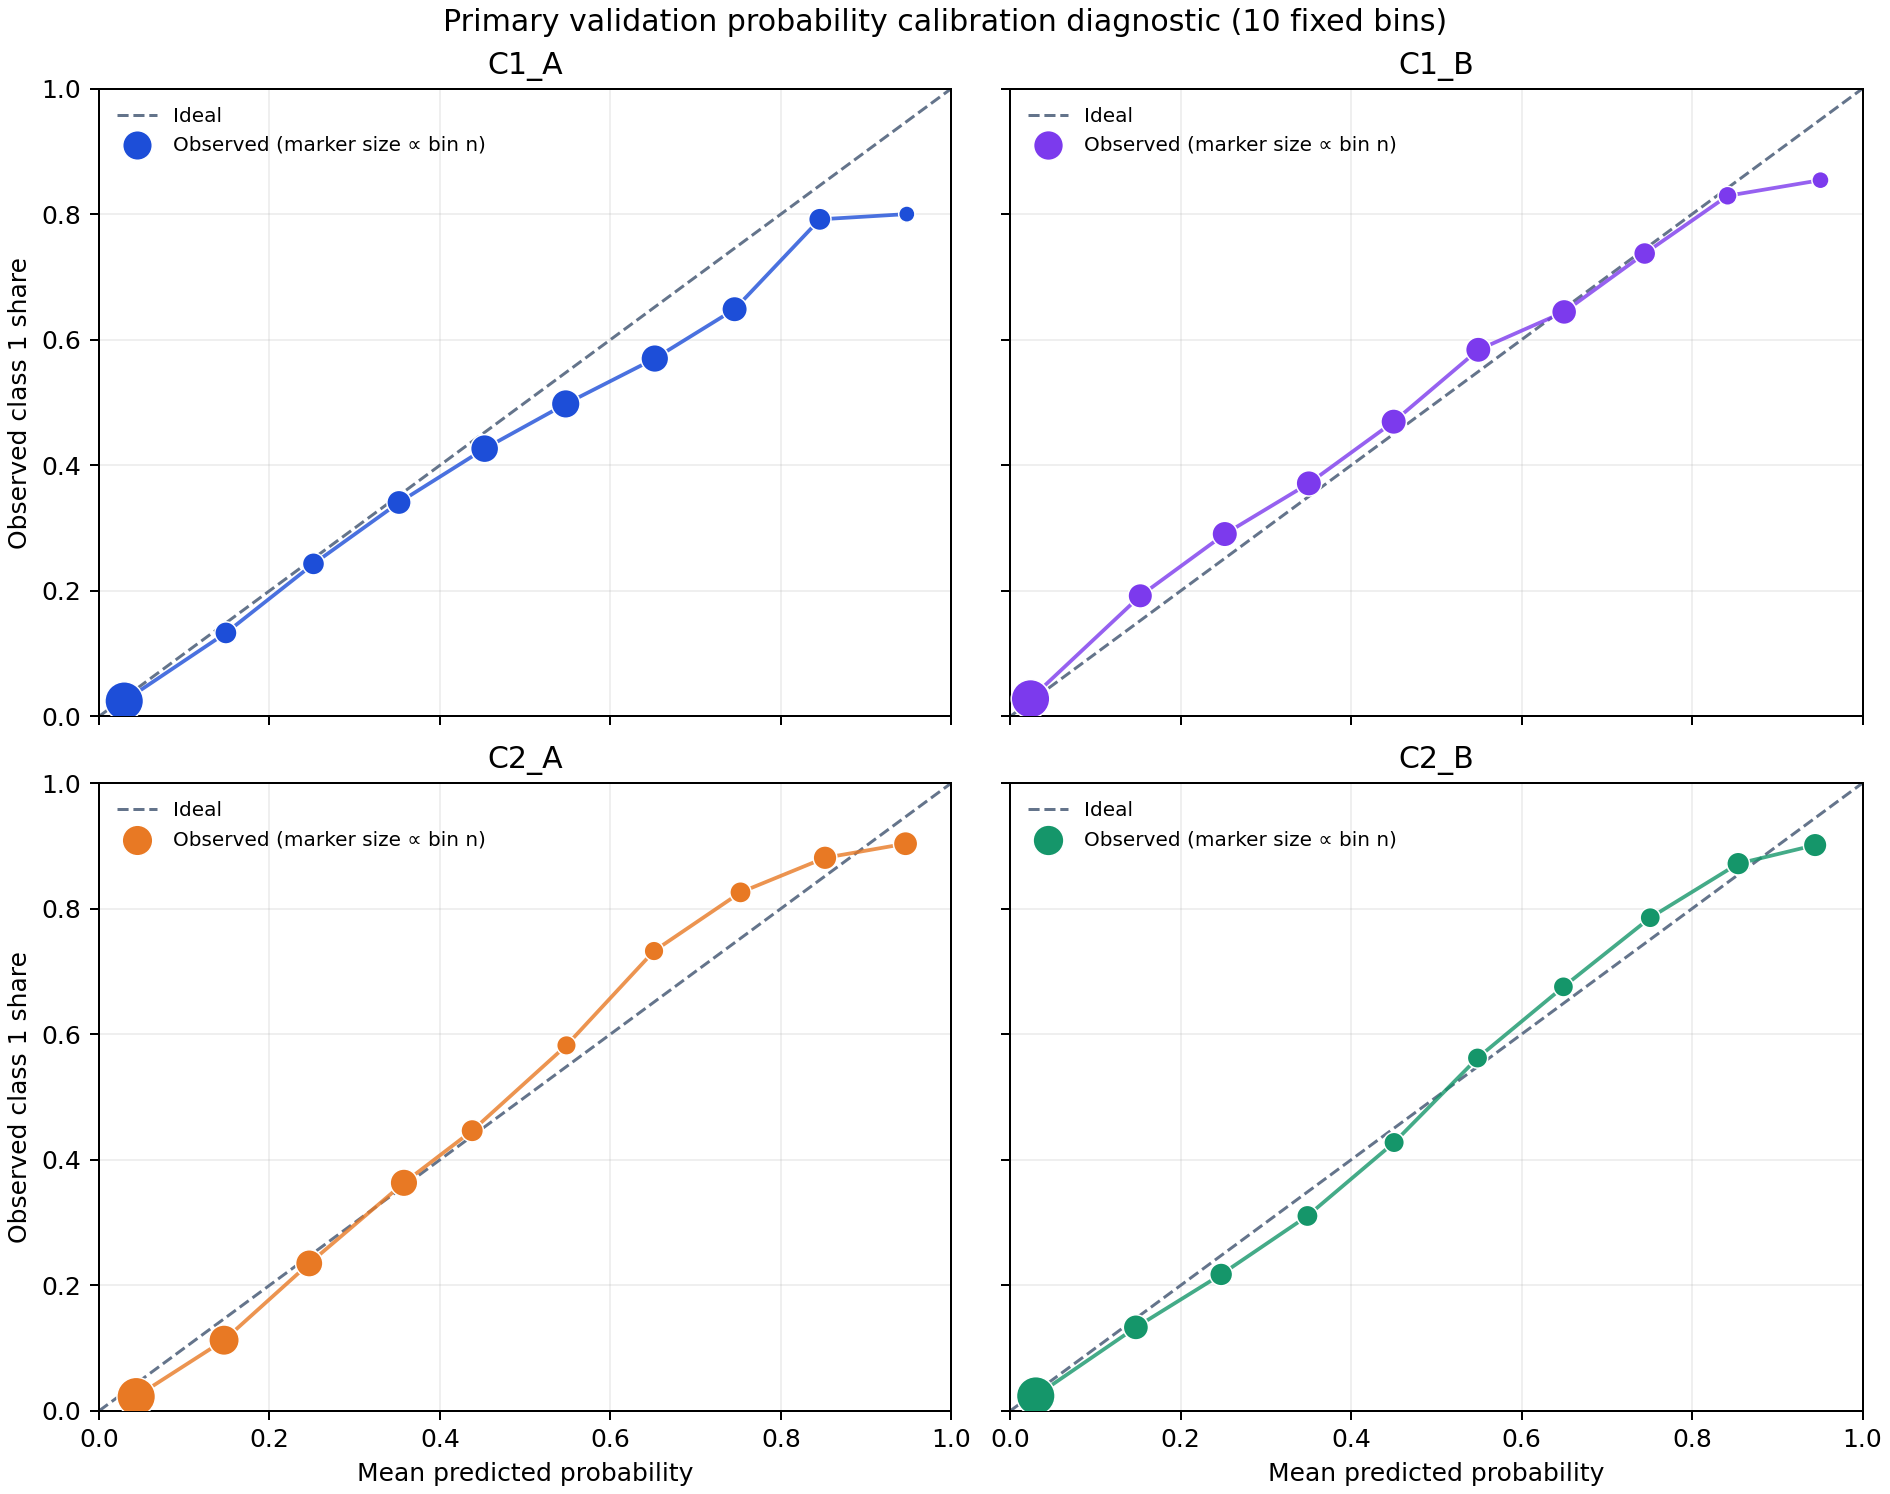

,model,older_fit_end,refreshed_fit_end,evaluation_cycles,n_same_rows,older_fixed_f1,refreshed_fixed_f1
4,C1_B,55,59,"[60, 63]",6493,0.6934,0.7662
5,C2_A,55,59,"[60, 63]",6493,0.7886,0.8193
6,C2_B,55,59,"[60, 63]",6493,0.7930,0.8471
11,C1_B,55,63,"[64, 67]",7078,0.6710,0.7228
12,C2_A,55,63,"[64, 67]",7078,0.7522,0.8037
13,C2_B,55,63,"[64, 67]",7078,0.7539,0.8257
18,C1_B,67,71,"[72, 75]",7462,0.6855,0.7212
19,C2_A,67,71,"[72, 75]",7462,0.7886,0.7937
20,C2_B,67,71,"[72, 75]",7462,0.7918,0.8040
25,C1_B,67,75,"[76, 79]",8491,0.6601,0.7037


In [8]:
display(pd.DataFrame([{'model':m,'Brier':P['fixed_0.5'][m]['metrics']['brier_score'],
  'mean probability':P['fixed_0.5'][m]['metrics']['mean_probability'],
  'actual prevalence':P['fixed_0.5'][m]['metrics']['positive_rate']} for m in ['C1_A','C1_B','C2_A','C2_B']]).round(4))
display(Image(filename=str(FIG/'classification_primary_reliability.png')))
paired=pd.DataFrame(verification['paired_history_diagnostics'])
display(paired[paired.model.isin(['C1_B','C2_A','C2_B'])][['model','older_fit_end','refreshed_fit_end',
 'evaluation_cycles','n_same_rows','older_fixed_f1','refreshed_fixed_f1']].round(4))

## Takeaways dan titik review

Ordinary TF-IDF sudah memberi informasi prediktif tambahan; NB-weighting/stacking TP1 belum diperlukan untuk menunjukkan manfaat text. Hybrid fixed 0,50 menjadi kandidat primary sementara, dengan text-only dan structured HGB sebagai kontrol penting. Belum ada final model atau jaminan skor Kaggle.

Prioritas Round 2 yang **belum dijalankan**:

1. Pisahkan pengaruh missing indicator, shared coefficients dan bobot blok text pada missing-stream trade-off; pertimbangkan kebijakan khusus stream dengan validasi temporal yang sama.
2. Uji threshold transfer/stability dengan inner history yang lebih representatif, tetap tanpa outer-label selection.
3. Pisahkan kontribusi cycle, kategori dan numeric fields untuk memahami late/horizon degradation.
4. Setelah kontrol tersebut, baru pertimbangkan NB weighting atau representasi text lain sebagai ablation terbatas.

QA: seluruh 56 evaluation jobs/112 policy-window metrics, 672 per-cycle metrics dan 36 threshold choices diperiksa independen dari vectors. Representative refit history 67 menguji semua keluarga; cakupannya tercatat pada verification receipt. Regression Round 1, raw dan TP1 dipertahankan.

Laporan: `reports/classification_round1/FINDINGS.md`; tabel detail: `comparison_tables.md`; metode/reproduksi: `docs/CLASSIFICATION_ROUND1.md`. **STOP setelah Round 1 untuk review pengguna.** Tidak ada Classification/Regression Round 2, official-test predictions, final model atau submission.